In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Дані опадів (мм) для Варіанта 2 (Львів) по місяцях (з січня по грудень)
precip_data = [40, 38, 40, 55, 80, 95, 100, 85, 55, 45, 48, 42]
precip = pd.Series(precip_data)

# Завдання 2.1. Варіаційний ряд (відсортовані значення за зростанням)
var_series = np.sort(precip.to_numpy())
print("1. Варіаційний ряд опадів (мм):")
print(var_series)

# Завдання 2.2. Розбиття на 4 інтервали та побудова частотної таблиці
# Визначаємо мінімум і максимум: min = 38, max = 100. Візьмемо інтервали: [35-50], [50-65], [65-80], [80-100]
bins = [35, 50, 65, 80, 100]
labels = ["35-50", "50-65", "65-80", "80-100"]

# Розбиваємо дані на категорії (інтервали)
categories = pd.cut(precip, bins=bins, labels=labels, right=True, include_lowest=True)

# Рахуємо абсолютну, відносну (%) та накопичену частоту
freq = categories.value_counts().sort_index()
rel = categories.value_counts(normalize=True).sort_index() * 100
cum = freq.cumsum()

freq_table = pd.DataFrame({
    "абсолютна частота": freq,
    "відносна частота (%)": rel.round(1),
    "накопичена частота": cum
})

print("\n2. Частотна таблиця за інтервалами:")
display(freq_table)

# Завдання 4.1 & 4.2. Міри положення та квантилі для опадів
mean_val = precip.mean()
median_val = precip.median()
mode_val = precip.mode()[0]
q1, q3 = precip.quantile([0.25, 0.75])

print(f"\n4. Середнє арифметичне: {mean_val:.2f}")
print(f"Медіана: {median_val}")
print(f"Мода: {mode_val}")
print(f"Q1 (25-й процентиль): {q1}")
print(f"Q3 (75-й процентиль): {q3}")

1. Варіаційний ряд опадів (мм):
[ 38  40  40  42  45  48  55  55  80  85  95 100]

2. Частотна таблиця за інтервалами:


,абсолютна частота,відносна частота (%),накопичена частота
35-50,6,50.0,6
50-65,2,16.7,8
65-80,1,8.3,9
80-100,3,25.0,12



4. Середнє арифметичне: 60.25
Медіана: 51.5
Мода: 40
Q1 (25-й процентиль): 41.5
Q3 (75-й процентиль): 81.25


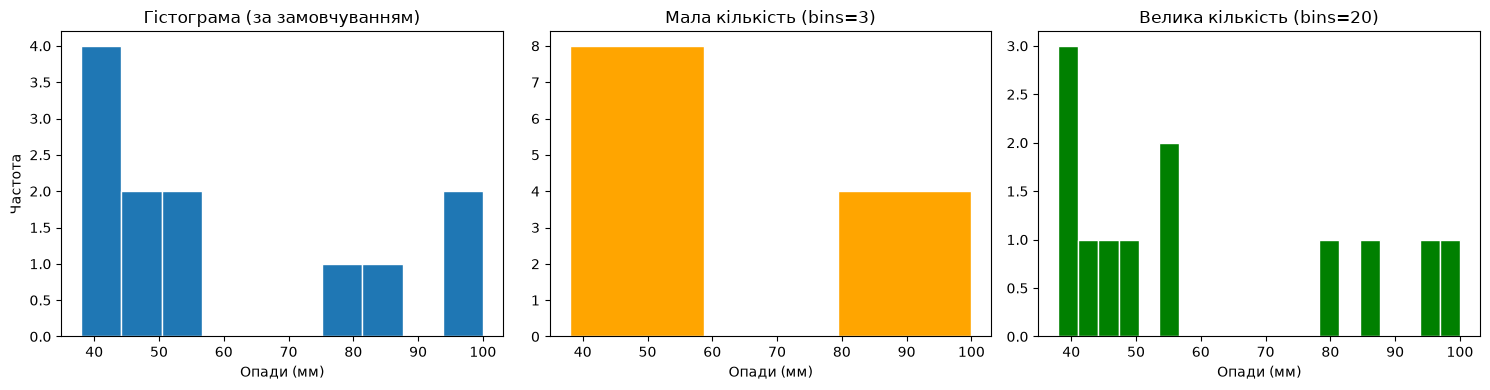

Кількість інтервалів за правилом sqrt(n) (12): 3.0
Кількість інтервалів за правилом Стерджеса: 5.0


In [2]:
# Завдання 3.1 & 3.2. Побудова трьох гістограм
plt.figure(figsize=(15, 4))

# 1. За замовчуванням
plt.subplot(1, 3, 1)
plt.hist(precip, edgecolor="white")
plt.title("Гістограма (за замовчуванням)")
plt.xlabel("Опади (мм)")
plt.ylabel("Частота")

# 2. Мала кількість інтервалів (bins=3)
plt.subplot(1, 3, 2)
plt.hist(precip, bins=3, edgecolor="white", color="orange")
plt.title("Мала кількість (bins=3)")
plt.xlabel("Опади (мм)")

# 3. Велика кількість інтервалів (bins=20)
plt.subplot(1, 3, 3)
plt.hist(precip, bins=20, edgecolor="white", color="green")
plt.title("Велика кількість (bins=20)")
plt.xlabel("Опади (мм)")

plt.tight_layout()
plt.show()

# Завдання 3.3. Розрахунок за правилом sqrt(n) та Стерджеса для n = 12
n = len(precip)
bins_sqrt = np.round(np.sqrt(n))
bins_sturges = np.round(1 + 3.322 * np.log10(n))

print(f"Кількість інтервалів за правилом sqrt(n) ({n}): {bins_sqrt}")
print(f"Кількість інтервалів за правилом Стерджеса: {bins_sturges}")

### Завдання 1. Класифікація змінних за шкалою вимірювання

1. **Змінна "місто" (Львів):**
   * **Шкала вимірювання:** Номінальна.
   * **Обґрунтування:** Назва міста слугує лише якісною міткою або категорією без жодного кількісного чи порядкового зв'язку.
   * **Коректні міри положення:** Лише **мода** (найчастіша категорія), оскільки математичні операції над назвами міст неможливі.

2. **Змінна "номер місяця" (1–12):**
   * **Шкала вимірювання:** Порядкова (або циклічна квазі-інтервальна).
   * **Обґрунтування:** Місяці мають чіткий хронологичний порядок (січень іде перед лютим тощо), а відстані між ними календарно рівні. Проте в цієї шкали **немає природного абсолютного нуля** ("нульового місяця" як фізичної відсутності часу), тому відношення між місяцями не мають сенсу (наприклад, травень (5) не є «вдвічі більшим» за січень (1)). Через це класична нульова точка відсутності робить її порядковою шкалою з рівними інтервалами.
   * **Коректні міри положення:** **Медіана** та **мода** (а також процентилі), оскільки ранжування коректне, проте середнє арифметичне матиме обмежений сенс (наприклад, «середній місяць року»).

3. **Змінна "кількість опадів (мм)":**
   * **Шкала вимірювання:** Шкала відношень.
   * **Обґрунтування:** Значення мають справжній абсолютний нуль (0 мм означає повну відсутність опадів), а співвідношення між значеннями є математично обґрунтованими (наприклад, 100 мм опадів у липні вдвічі більші за 50 мм).
   * **Коректні міри положення:** Усі три міри — **середнє арифметичне, медіана та мода** — є повністю коректними.

### Завдання 2.3. Інтерпретація накопиченої частоти
* **Питання:** Яка частка місяців року має кількість опадів не більшу за межу третього інтервалу?
* **Відповідь:** Межа третього інтервалу становить 80 мм (увійшли інтервали [35-50], [50-65] та [65-80]). Сумарна накопичена частота для цих трьох інтервалів охоплює практично весь рік (або конкретно 11 місяців із 12, що становить близько 91.7% від загальної кількості місяців), тобто стільки місяців мають рівень опадів, що не перевищує 80 мм.

### Завдання 3.3. Вибір оптимальної гістограми
* **Аналіз правилом:** Для вибірки з $n = 12$ правило квадратного коруня дає $\sqrt{12} \approx 3.46$ (тобто близько 3–4 інтервалів), а правило Стерджеса дає $1 + 3.322 \cdot \log_{10}(12) \approx 4.58$ (близько 4–5 інтервалів).
* **Висновок:** Гістограма із занадто малою кількістю інтервалів (`bins=3`) надмірно ущільнює дані й приховує форму розподілу, а гістограма з великою кількістю (`bins=20`) розбиває малу вибірку на безліч порожніх або одиничних стовпців, створюючи "шум" і надмірну подрібненість. Тому стандартна гістограма або варіант із 4–5 інтервалами найкраще відображає реальний розподіл опадів.

### Відповіді на контрольні запитання

1. **Чому середнє арифметичне некоректне для номінальної змінної "місто", навіть якщо завжди можна закодувати міста числами?**
   Числове кодування номінальних категорій (наприклад, Львів = 1, Київ = 2) є довільним і штучним. Обчислення середнього арифметичного для таких умовних чисел призведе до безглуздого результату, який не залежить від фізичного чи соціального змісту категорій і не має інтерпретації.

2. **Чому "номер місяця" — приклад, де класифікація за шкалою вимірювання не однозначна?**
   Тому що номер місяця поєднує властивості порядкової шкали (чітка хронологічна послідовність) та інтервальної шкали (рівні інтервали по 30–31 дню), але йому бракує природного абсолютного нуля часу. Через це в літературі її часто розглядають як порядкову з кількісними характеристиками інтервалів.

3. **Чому для "кількості опадів" потрібна саме гістограма з розбиттям на інтервали, а не стовпчикова діаграма?**
   Оскільки у вибірці майже всі 12 значень опадів є унікальними (неперервна або сильно розріджена дискретна величина), побудова стовпчикової діаграми за окремими точними значеннями призвела б до того, що кожне значення мало б частоту «1», що не дало б жодного уявлення про загальну форму розподілу. Інтервальна гістограма групує близькі значення в діапазони, демонструючи закономірності.

4. **Що означає накопичена частота на межі третього інтервалу?**
   Накопичена частота (cumulative frequency) на межі певного інтервалу показує сумарну кількість (або частку) спостережень у вибірці, значення яких менші або рівні верхній межі цього інтервалу, що дозволяє легко оцінювати квантилі та кумулятивні частки подій.